# BlinkIT Grocery Sales Analysis

**Domain:** Retail & Grocery Sales Analytics  
**Company:** Sapphire IQ  
**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook

---

## Project Context
I am working as a Data Analyst at Sapphire IQ. Management wants to know how BlinkIT's grocery business is performing, so in this project I will:

1. Understand the business and its sales performance
2. Check that the data is reliable (clean it)
3. Find out what is driving better sales
4. Give management clear insights and practical suggestions

The notebook follows the **four objectives** of the project, and each task (1.1, 1.2, ...) has its own section.

## Importing Libraries and Loading the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set_style('whitegrid')

In [2]:
# loading the dataset
df = pd.read_excel('BlinkIT_Grocery_Data.xlsx')

# keeping a copy of the original data, just in case I need it later
df_raw = df.copy()

df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


---
# Objective 1: Understand the Business and Its Sales Performance

## Task 1.1: What types of products is BlinkIT selling?

In [3]:
# size of the data
print('Rows    :', df.shape[0])
print('Columns :', df.shape[1])
print()
print(df.columns.tolist())

Rows    : 8523
Columns : 12

['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Establishment Year', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility', 'Item Weight', 'Sales', 'Rating']


In [4]:
# data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   str    
 1   Item Identifier            8523 non-null   str    
 2   Item Type                  8523 non-null   str    
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   str    
 5   Outlet Location Type       8523 non-null   str    
 6   Outlet Size                8523 non-null   str    
 7   Outlet Type                8523 non-null   str    
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [5]:
# how many different products and product types are there?
print('Unique products (Item Identifier):', df['Item Identifier'].nunique())
print('Unique product types (Item Type) :', df['Item Type'].nunique())
print()
print(df['Item Type'].value_counts())

Unique products (Item Identifier): 1559
Unique product types (Item Type) : 16

Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64


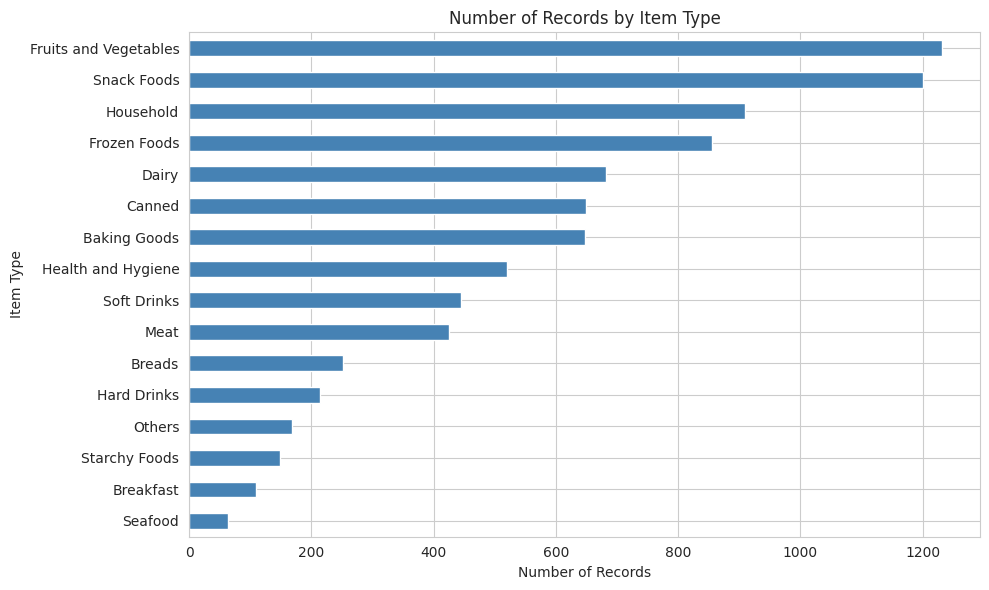

In [6]:
plt.figure(figsize=(10, 6))
df['Item Type'].value_counts().sort_values().plot(kind='barh', color='steelblue')
plt.title('Number of Records by Item Type')
plt.xlabel('Number of Records')
plt.ylabel('Item Type')
plt.tight_layout()
plt.show()

In [7]:
# fat content of the products (this column looks messy, I will fix it in Objective 2)
df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

**Observation:**
- The data has **8,523 records** and **12 columns**. It contains **1,559 different products** that fall under **16 item types**.
- **Fruits and Vegetables** (1,232 records) and **Snack Foods** (1,200 records) are the most common item types. **Seafood** (64 records) is the least common.
- The fat content column has 5 different labels (`Low Fat`, `low fat`, `LF`, `Regular`, `reg`), but really there are only 2 types. This needs cleaning.

## Task 1.2: What are the types and locations of the outlets?

In [8]:
print('Number of outlets:', df['Outlet Identifier'].nunique())
print()
print('Outlet Type:')
print(df['Outlet Type'].value_counts())
print()
print('Outlet Location Type:')
print(df['Outlet Location Type'].value_counts())
print()
print('Outlet Size:')
print(df['Outlet Size'].value_counts())

Number of outlets: 10

Outlet Type:
Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

Outlet Location Type:
Outlet Location Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64

Outlet Size:
Outlet Size
Medium    3631
Small     3139
High      1753
Name: count, dtype: int64


In [9]:
# one row per outlet, to see the outlet details clearly
outlet_info = df.groupby('Outlet Identifier')[['Outlet Type', 'Outlet Location Type', 'Outlet Establishment Year']].first()
outlet_info['Records'] = df['Outlet Identifier'].value_counts()
outlet_info

,Outlet Type,Outlet Location Type,Outlet Establishment Year,Records
Outlet Identifier,,,,
OUT010,Grocery Store,Tier 3,2011,555
OUT013,Supermarket Type1,Tier 3,2014,932
OUT017,Supermarket Type1,Tier 2,2020,926
OUT018,Supermarket Type2,Tier 3,2022,928
OUT019,Grocery Store,Tier 1,2018,528
OUT027,Supermarket Type3,Tier 3,2018,935
OUT035,Supermarket Type1,Tier 2,2017,930
OUT045,Supermarket Type1,Tier 2,2015,929
OUT046,Supermarket Type1,Tier 1,2016,930


In [10]:
# how many outlets of each type and each location are there?
unique_outlets = df.drop_duplicates('Outlet Identifier')

print('Outlets by Type:')
print(unique_outlets['Outlet Type'].value_counts())
print()
print('Outlets by Location Tier:')
print(unique_outlets['Outlet Location Type'].value_counts())

Outlets by Type:
Outlet Type
Supermarket Type1    6
Grocery Store        2
Supermarket Type2    1
Supermarket Type3    1
Name: count, dtype: int64

Outlets by Location Tier:
Outlet Location Type
Tier 3    4
Tier 1    3
Tier 2    3
Name: count, dtype: int64


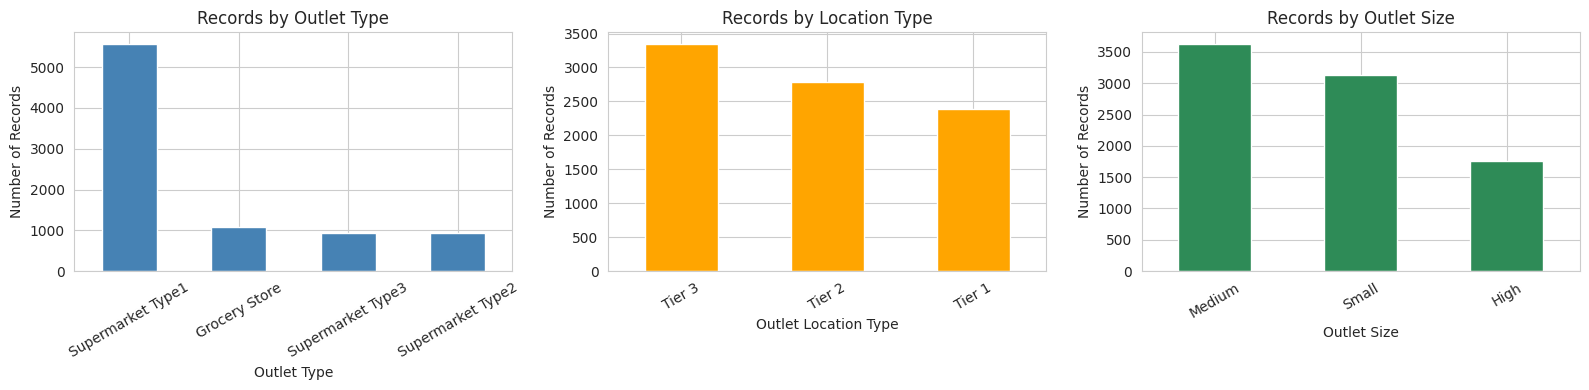

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

df['Outlet Type'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Records by Outlet Type')

df['Outlet Location Type'].value_counts().plot(kind='bar', ax=axes[1], color='orange')
axes[1].set_title('Records by Location Type')

df['Outlet Size'].value_counts().plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Records by Outlet Size')

for ax in axes:
    ax.set_ylabel('Number of Records')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Observation:**
- BlinkIT has **10 outlets**: 6 are *Supermarket Type1*, 2 are *Grocery Stores*, 1 is *Supermarket Type2* and 1 is *Supermarket Type3*.
- The outlets are spread across 3 location tiers: **Tier 1 (3 outlets), Tier 2 (3 outlets) and Tier 3 (4 outlets)**.
- The outlets were established between **2011 and 2022**.
- The two *Grocery Stores* (OUT010 and OUT019) have far fewer records (555 and 528) than the other outlets (about 930 each).
- Outlet Size looks strange for some outlets: OUT010, OUT017 and OUT045 each show more than one size. I will check this in Task 2.4.

## Task 1.3: How much is BlinkIT selling overall?

In [12]:
total_sales = df['Sales'].sum()
print('Total Sales   :', round(total_sales, 2))
print('Average Sales :', round(df['Sales'].mean(), 2))
print('Median Sales  :', round(df['Sales'].median(), 2))
print('Minimum Sales :', round(df['Sales'].min(), 2))
print('Maximum Sales :', round(df['Sales'].max(), 2))

Total Sales   : 1201681.49
Average Sales : 140.99
Median Sales  : 143.01
Minimum Sales : 31.29
Maximum Sales : 266.89


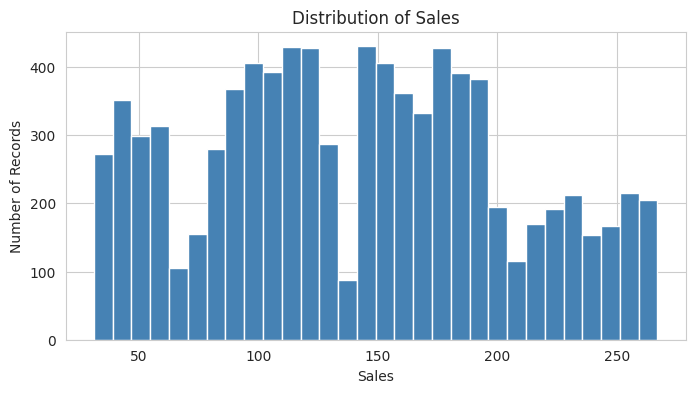

In [13]:
plt.figure(figsize=(8, 4))
plt.hist(df['Sales'], bins=30, color='steelblue', edgecolor='white')
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Number of Records')
plt.show()

**Observation:**
- BlinkIT's total sales in this data are about **1,201,681**.
- A single record has an average sale of about **141**, ranging from about **31** to **267**.
- The mean (141) and median (143) are very close, so the sales are fairly evenly spread and not heavily skewed.

## Task 1.4: What is the overall customer rating and product performance?

In [14]:
print('Average Rating:', round(df['Rating'].mean(), 2))
print('Minimum Rating:', df['Rating'].min())
print('Maximum Rating:', df['Rating'].max())

Average Rating: 3.97
Minimum Rating: 1.0
Maximum Rating: 5.0


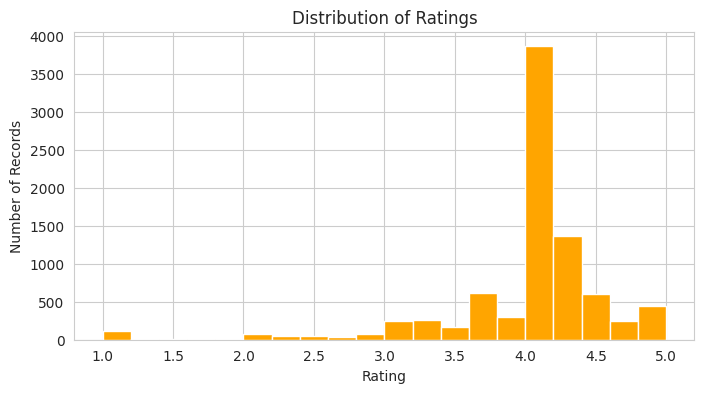

In [15]:
plt.figure(figsize=(8, 4))
plt.hist(df['Rating'], bins=20, color='orange', edgecolor='white')
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Records')
plt.show()

In [16]:
# product performance: sales and rating for each item type
product_perf = df.groupby('Item Type').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Average_Rating=('Rating', 'mean')
).round(2)

product_perf.sort_values('Total_Sales', ascending=False)

,Total_Sales,Average_Sales,Average_Rating
Item Type,,,
Fruits and Vegetables,178124.08,144.58,3.96
Snack Foods,175433.92,146.19,3.95
Household,135976.53,149.42,4.00
Frozen Foods,118558.88,138.50,3.97
Dairy,101276.46,148.50,3.97
Canned,90706.73,139.76,3.99
Baking Goods,81894.74,126.38,3.98
Health and Hygiene,68025.84,130.82,3.99
Meat,59449.86,139.88,4.02


**Observation:**
- The overall average customer rating is about **3.97 out of 5**, which is good.
- Most ratings are around 4.0 (4.0 alone is about 39% of all records). A few products have very low ratings (as low as 1.0).
- Average rating is almost the same for all item types (all close to 4). Only the sales are very different between item types.

---
# Objective 2: Make Sure the Available Information Is Reliable

Before finding insights, I need to check the data quality: missing values, duplicates, unusual values and inconsistent labels.

## Task 2.1: Find missing information

In [17]:
missing = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df) * 100).round(2)

pd.DataFrame({'Missing Values': missing, 'Missing %': missing_percent})

,Missing Values,Missing %
Item Fat Content,0,0.00
Item Identifier,0,0.00
Item Type,0,0.00
Outlet Establishment Year,0,0.00
Outlet Identifier,0,0.00
Outlet Location Type,0,0.00
Outlet Size,0,0.00
Outlet Type,0,0.00
Item Visibility,0,0.00
Item Weight,1463,17.17


In [18]:
# only Item Weight has missing values. Let me see which outlets they come from
df[df['Item Weight'].isnull()]['Outlet Identifier'].value_counts()

Outlet Identifier
OUT027    935
OUT019    528
Name: count, dtype: int64

In [19]:
# does one product always have the same weight?
# (if yes, I can use the weight of the same product from other outlets)
df.groupby('Item Identifier')['Item Weight'].nunique().value_counts()

Item Weight
1    1555
0       4
Name: count, dtype: int64

**Observation:**
- Only **Item Weight** has missing values: **1,463 records (about 17%)**.
- All the missing weights come from just **two outlets: OUT019 and OUT027**. These outlets did not record the weight at all.
- Each product has only one weight value (nunique is 1), so a product's weight is the same in every outlet. I can fill the missing weight using the same product's weight from the other outlets.

In [20]:
# Step 1: fill missing weight using the same product's weight from other outlets
item_avg_weight = df.groupby('Item Identifier')['Item Weight'].transform('mean')
df['Item Weight'] = df['Item Weight'].fillna(item_avg_weight)

print('Missing weights after step 1:', df['Item Weight'].isnull().sum())

Missing weights after step 1: 4


In [21]:
# Step 2: a few products are only sold in OUT019 / OUT027, so they have no weight anywhere.
# For these I will use the average weight of their Item Type.
type_avg_weight = df.groupby('Item Type')['Item Weight'].transform('mean')
df['Item Weight'] = df['Item Weight'].fillna(type_avg_weight)

print('Missing weights after step 2:', df['Item Weight'].isnull().sum())

Missing weights after step 2: 0


**Result:** All missing weights are filled. I used the product's own weight where possible, and the item type average for the few products that had no weight anywhere.

## Task 2.2: Find repeated (duplicate) information

In [22]:
# completely duplicated rows
print('Fully duplicated rows:', df.duplicated().sum())

# the same product in the same outlet more than once
print('Same product + same outlet repeated:', df.duplicated(subset=['Item Identifier', 'Outlet Identifier']).sum())

# a product ID appears many times
print('Repeated Item Identifiers:', df['Item Identifier'].duplicated().sum())

Fully duplicated rows: 0
Same product + same outlet repeated: 0
Repeated Item Identifiers: 6964


**Observation:**
- There are **no duplicate rows** in the data, and no product is repeated inside the same outlet.
- The *Item Identifier* repeats a lot, but that is normal: the same product is sold in many different outlets. So these are **not** duplicates and nothing needs to be removed.

## Task 2.3: Find unusually high or low values

In [23]:
df[['Item Visibility', 'Item Weight', 'Sales', 'Rating', 'Outlet Establishment Year']].describe().round(3)

,Item Visibility,Item Weight,Sales,Rating,Outlet Establishment Year
count,8523.000,8523.000,8523.000,8523.000,8523.000
mean,0.066,12.875,140.993,3.966,2016.451
std,0.052,4.645,62.275,0.606,3.189
min,0.000,4.555,31.290,1.000,2011.000
25%,0.027,8.785,93.826,4.000,2014.000
50%,0.054,12.650,143.013,4.000,2016.000
75%,0.095,16.850,185.644,4.200,2018.000
max,0.328,21.350,266.888,5.000,2022.000


In [24]:
# Item Visibility is the % of shelf space a product gets. The minimum is 0, which looks wrong
# because a product that is on sale must have some visibility.
print('Records with zero visibility:', (df['Item Visibility'] == 0).sum())

Records with zero visibility: 526


**Observation:** There are **526 records** where Item Visibility is exactly 0. A product being sold with 0 visibility is not realistic, so this is an *unusually low* value caused by missing information. I will treat these zeros as missing and replace them with the average visibility of the same product in other outlets.

In [25]:
# replace 0 with NaN, then fill with the same product's average visibility
df['Item Visibility'] = df['Item Visibility'].replace(0, np.nan)

item_avg_vis = df.groupby('Item Identifier')['Item Visibility'].transform('mean')
df['Item Visibility'] = df['Item Visibility'].fillna(item_avg_vis)

# if still something is missing, use the overall average
df['Item Visibility'] = df['Item Visibility'].fillna(df['Item Visibility'].mean())

print('Zero visibility left :', (df['Item Visibility'] == 0).sum())
print('Missing visibility   :', df['Item Visibility'].isnull().sum())

Zero visibility left : 0
Missing visibility   : 0


In [26]:
# now check for outliers using the IQR method
num_cols = ['Item Visibility', 'Item Weight', 'Sales', 'Rating']

for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, '| lower limit:', round(lower, 3), '| upper limit:', round(upper, 3), '| outliers:', count)

Item Visibility | lower limit: -0.07 | upper limit: 0.2 | outliers: 144
Item Weight | lower limit: -3.313 | upper limit: 28.948 | outliers: 0
Sales | lower limit: -43.899 | upper limit: 323.37 | outliers: 0
Rating | lower limit: 3.7 | upper limit: 4.5 | outliers: 1931


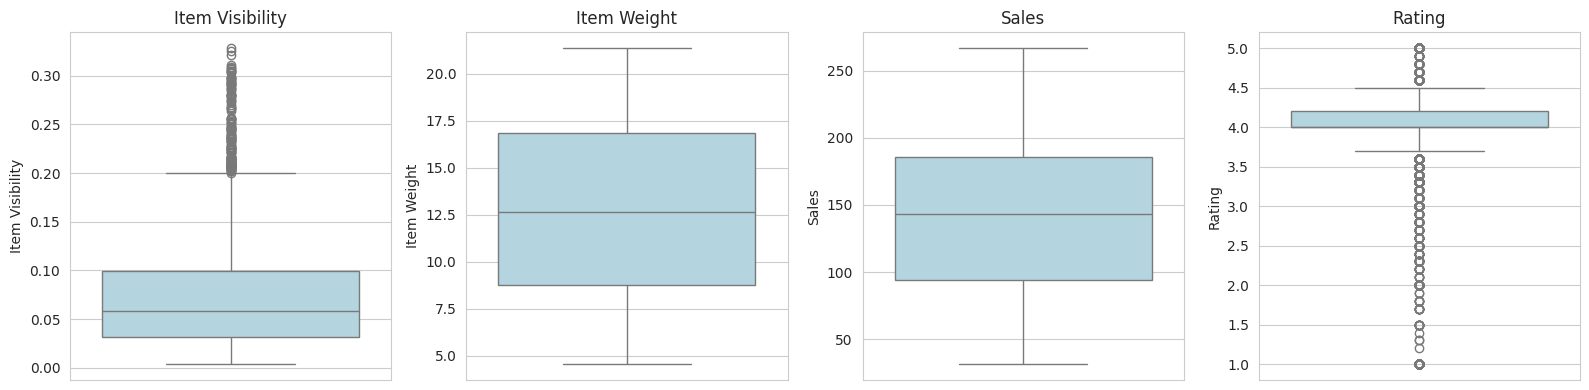

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    sns.boxplot(y=df[num_cols[i]], ax=axes[i], color='lightblue')
    axes[i].set_title(num_cols[i])

plt.tight_layout()
plt.show()

**Observation:**
- **Item Visibility** has some high outliers (maximum about 0.33, i.e. 33% of shelf space). These are possible values (some products get a lot of space), so I am **keeping them**.
- **Item Weight** and **Sales** have no outliers.
- **Rating** shows a large number of "outliers" (1,931 records). This is because most ratings are squeezed very close to 4.0, so the IQR limits are very narrow (3.7 to 4.5). Ratings anywhere from 1 to 5 are valid customer opinions, so I am **keeping them** too.
- The establishment years (2011 to 2022) and the sales range look normal.

## Task 2.4: Make similar information consistent

In [28]:
# Problem 1: fat content has 5 labels for 2 types
print('Before:')
print(df['Item Fat Content'].value_counts())

df['Item Fat Content'] = df['Item Fat Content'].replace({'LF': 'Low Fat', 'low fat': 'Low Fat', 'reg': 'Regular'})

print()
print('After:')
print(df['Item Fat Content'].value_counts())

Before:
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

After:
Item Fat Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64


In [29]:
# Problem 2: non-food items (Item Identifier starts with NC) like Household are marked "Low Fat",
# which does not make sense. Let me check.
nc_items = df[df['Item Identifier'].str.startswith('NC')]
print(nc_items['Item Type'].unique())
print(nc_items['Item Fat Content'].value_counts())

<StringArray>
['Health and Hygiene', 'Household', 'Others']
Length: 3, dtype: str
Item Fat Content
Low Fat    1599
Name: count, dtype: int64


In [30]:
# non-consumable items cannot have fat content, so I will label them "Non-Edible"
df.loc[df['Item Identifier'].str.startswith('NC'), 'Item Fat Content'] = 'Non-Edible'

df['Item Fat Content'].value_counts()

Item Fat Content
Low Fat       3918
Regular       3006
Non-Edible    1599
Name: count, dtype: int64

In [31]:
# Problem 3: check for extra spaces in the text columns
text_cols = ['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Identifier',
             'Outlet Location Type', 'Outlet Size', 'Outlet Type']

for col in text_cols:
    df[col] = df[col].str.strip()

print('Text columns cleaned')

Text columns cleaned


In [32]:
# Problem 4: outlet size should be one value per outlet. Let me check.
df.groupby('Outlet Identifier')['Outlet Size'].nunique()

Outlet Identifier
OUT010    3
OUT013    1
OUT017    3
OUT018    1
OUT019    1
OUT027    1
OUT035    1
OUT045    3
OUT046    1
OUT049    1
Name: Outlet Size, dtype: int64

In [33]:
# see the sizes for the 3 outlets that have more than one size
df[df['Outlet Identifier'].isin(['OUT010', 'OUT017', 'OUT045'])].groupby(['Outlet Identifier', 'Outlet Size']).size()

Outlet Identifier  Outlet Size
OUT010             High           233
                   Medium         265
                   Small           57
OUT017             High           314
                   Medium         244
                   Small          368
OUT045             High           274
                   Medium         329
                   Small          326
dtype: int64

**Observation:**
- Fat content is now consistent: **Low Fat**, **Regular**, and **Non-Edible** (for household/health items).
- Three outlets (**OUT010, OUT017, OUT045**) have more than one Outlet Size, and the records are split almost equally between the sizes (for example OUT045 has 274 High, 329 Medium and 326 Small). One physical outlet cannot have 3 different sizes, so this column is unreliable for these outlets.
- I cannot know which size is the correct one, so I am **not changing it**. I will just be careful when I draw conclusions from Outlet Size and rely more on Outlet Type and Location.

In [34]:
# final check of the cleaned data
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Shape:', df.shape)

# saving the cleaned data
df.to_csv('BlinkIT_Grocery_Cleaned.csv', index=False)

Missing values: 0
Duplicate rows: 0
Shape: (8523, 12)


---
# Objective 3: Find Out What Is Driving Better Sales Performance

## Task 3.1: Which types of products are selling more?

In [35]:
item_sales = df.groupby('Item Type')['Sales'].agg(['sum', 'mean', 'count']).round(2)
item_sales.columns = ['Total_Sales', 'Average_Sales', 'Number_of_Records']
item_sales = item_sales.sort_values('Total_Sales', ascending=False)
item_sales

,Total_Sales,Average_Sales,Number_of_Records
Item Type,,,
Fruits and Vegetables,178124.08,144.58,1232
Snack Foods,175433.92,146.19,1200
Household,135976.53,149.42,910
Frozen Foods,118558.88,138.50,856
Dairy,101276.46,148.50,682
Canned,90706.73,139.76,649
Baking Goods,81894.74,126.38,648
Health and Hygiene,68025.84,130.82,520
Meat,59449.86,139.88,425


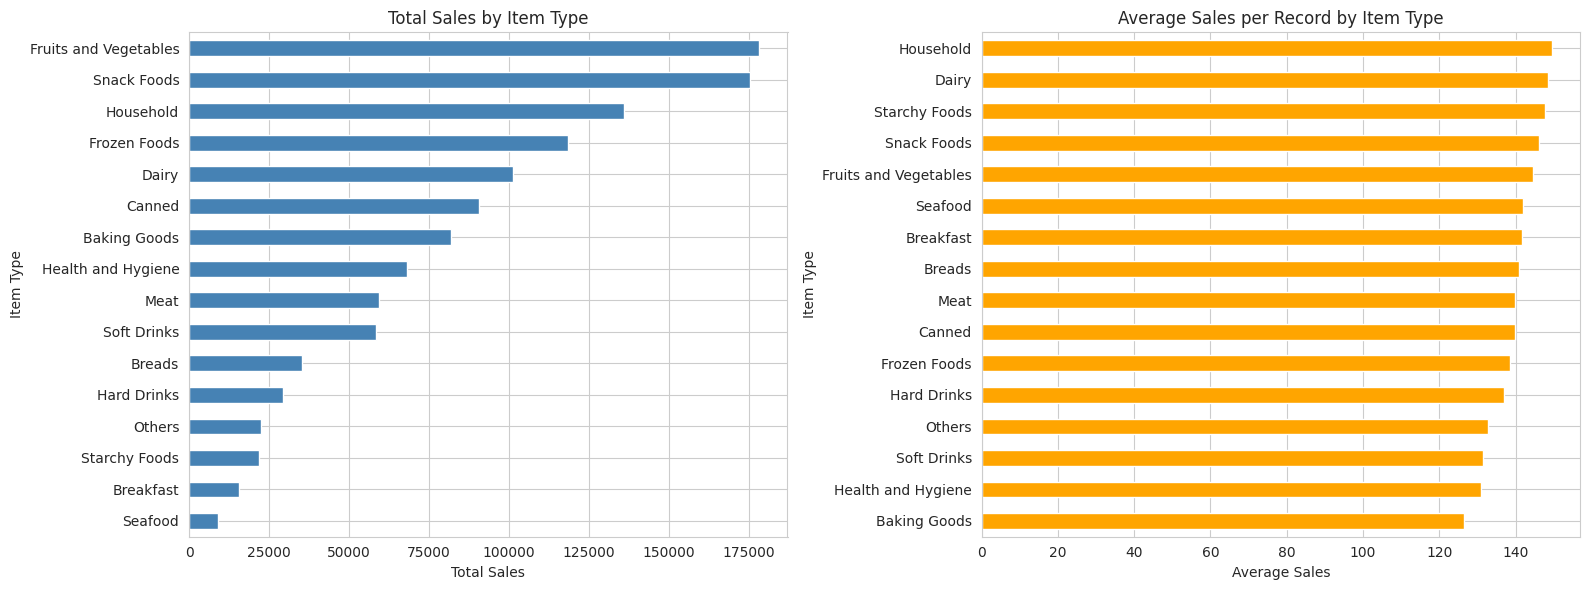

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

item_sales['Total_Sales'].sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Total Sales by Item Type')
axes[0].set_xlabel('Total Sales')

item_sales['Average_Sales'].sort_values().plot(kind='barh', ax=axes[1], color='orange')
axes[1].set_title('Average Sales per Record by Item Type')
axes[1].set_xlabel('Average Sales')

plt.tight_layout()
plt.show()

In [37]:
# sales by fat content
fat_sales = df.groupby('Item Fat Content')['Sales'].agg(['sum', 'mean', 'count']).round(2)
fat_sales

,sum,mean,count
Item Fat Content,,,
Low Fat,549865.43,140.34,3918
Non-Edible,226454.26,141.62,1599
Regular,425361.80,141.50,3006


In [38]:
# creating a new column: Food, Drinks or Non-Consumable (from the first 2 letters of the Item Identifier)
df['Item Category'] = df['Item Identifier'].str[:2].map({'FD': 'Food', 'DR': 'Drinks', 'NC': 'Non-Consumable'})

category_sales = df.groupby('Item Category')['Sales'].agg(['sum', 'mean', 'count']).round(2)
category_sales

,sum,mean,count
Item Category,,,
Drinks,104650.23,130.98,799
Food,870577.01,142.14,6125
Non-Consumable,226454.26,141.62,1599


**Observation:**
- **Fruits and Vegetables** (about 178,124), **Snack Foods** (about 175,434) and **Household** (about 135,977) are the top 3 item types by total sales. **Seafood** (about 9,078) is the lowest.
- But *total* sales mostly follow the *number of records*: item types with more products naturally sell more in total.
- When we look at *average sales per record*, **Household (149.4), Dairy (148.5) and Starchy Foods (147.8)** are the best, while **Baking Goods (126.4), Health and Hygiene (130.8) and Soft Drinks (131.5)** are the weakest.
- Food is the biggest category in total sales (about 870,577). Food (142.1) and Non-Consumable items (141.6) have similar average sales per record, but **Drinks are lower (131.0)** and also have the smallest total (about 104,650).

## Task 3.2: Which types of outlets are performing better?

In [39]:
# Outlet Type
type_sales = df.groupby('Outlet Type')['Sales'].agg(['sum', 'mean', 'count']).round(2)
type_sales.columns = ['Total_Sales', 'Average_Sales', 'Number_of_Records']
type_sales['Average_Rating'] = df.groupby('Outlet Type')['Rating'].mean().round(2)
type_sales

,Total_Sales,Average_Sales,Number_of_Records,Average_Rating
Outlet Type,,,,
Grocery Store,151939.15,140.29,1083,3.99
Supermarket Type1,787549.89,141.21,5577,3.96
Supermarket Type2,131477.78,141.68,928,3.97
Supermarket Type3,130714.67,139.80,935,3.95


In [40]:
# Outlet Location Type
loc_sales = df.groupby('Outlet Location Type')['Sales'].agg(['sum', 'mean', 'count']).round(2)
loc_sales.columns = ['Total_Sales', 'Average_Sales', 'Number_of_Records']
loc_sales['Average_Rating'] = df.groupby('Outlet Location Type')['Rating'].mean().round(2)
loc_sales

,Total_Sales,Average_Sales,Number_of_Records,Average_Rating
Outlet Location Type,,,,
Tier 1,336397.81,140.87,2388,3.98
Tier 2,393150.65,141.17,2785,3.96
Tier 3,472133.03,140.94,3350,3.96


In [41]:
# Outlet Size (remember: this column is unreliable for 3 outlets)
size_sales = df.groupby('Outlet Size')['Sales'].agg(['sum', 'mean', 'count']).round(2)
size_sales.columns = ['Total_Sales', 'Average_Sales', 'Number_of_Records']
size_sales['Average_Rating'] = df.groupby('Outlet Size')['Rating'].mean().round(2)
size_sales

,Total_Sales,Average_Sales,Number_of_Records,Average_Rating
Outlet Size,,,,
High,248991.59,142.04,1753,3.95
Medium,507895.74,139.88,3631,3.98
Small,444794.17,141.70,3139,3.96


In [42]:
# each outlet
outlet_sales = df.groupby('Outlet Identifier')['Sales'].agg(['sum', 'mean', 'count']).round(2)
outlet_sales.columns = ['Total_Sales', 'Average_Sales', 'Number_of_Records']
outlet_sales['Average_Rating'] = df.groupby('Outlet Identifier')['Rating'].mean().round(2)
outlet_sales = outlet_sales.sort_values('Total_Sales', ascending=False)
outlet_sales

,Total_Sales,Average_Sales,Number_of_Records,Average_Rating
Outlet Identifier,,,,
OUT035,133103.91,143.12,930,3.94
OUT046,132113.37,142.06,930,3.96
OUT013,131809.02,141.43,932,3.95
OUT018,131477.78,141.68,928,3.97
OUT045,130942.78,140.95,929,3.96
OUT027,130714.67,139.80,935,3.95
OUT049,130476.86,140.30,930,3.99
OUT017,129103.96,139.42,926,3.98
OUT010,78131.57,140.78,555,3.98


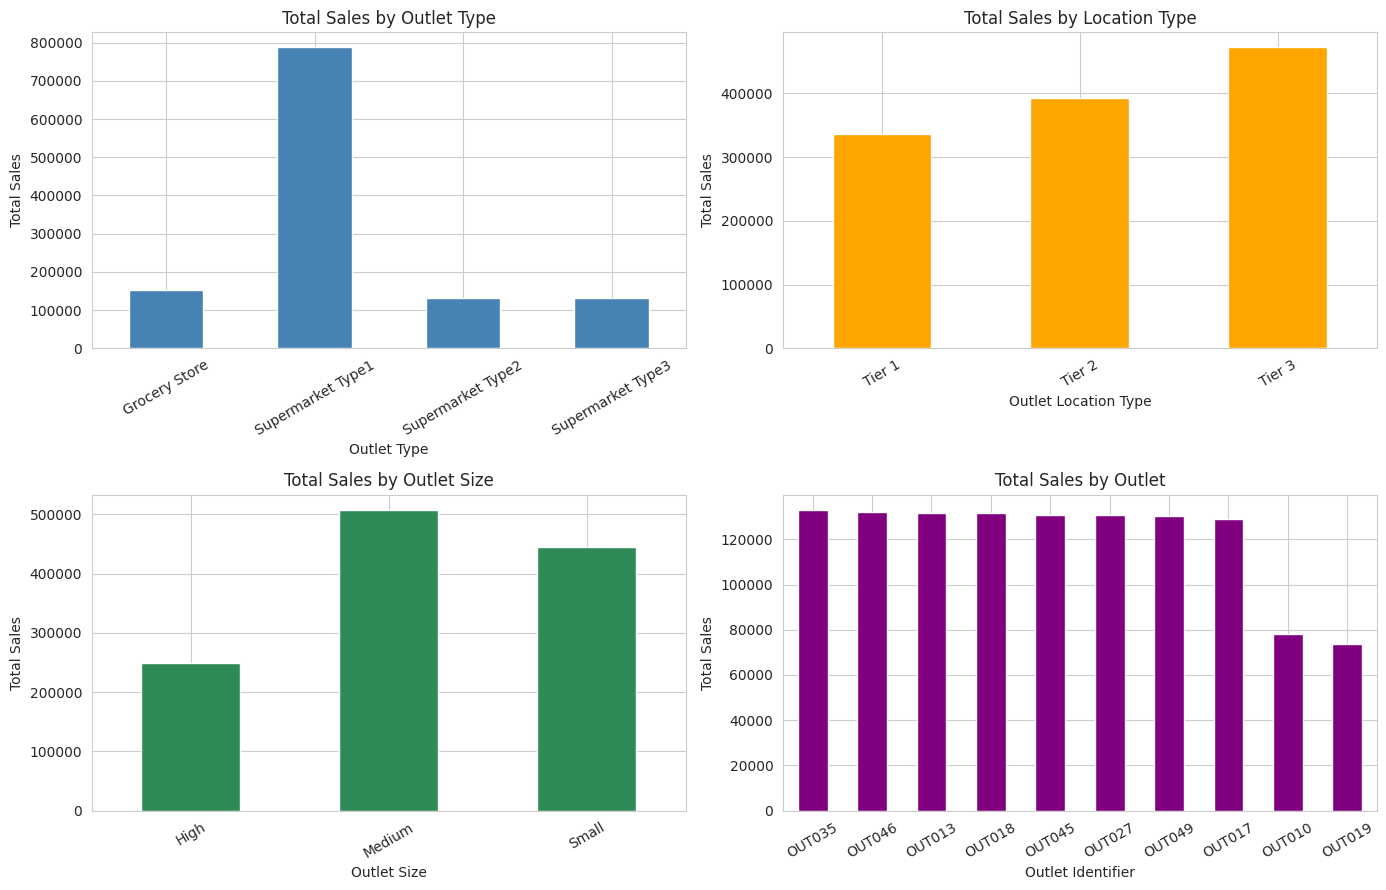

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

type_sales['Total_Sales'].plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Total Sales by Outlet Type')

loc_sales['Total_Sales'].plot(kind='bar', ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Total Sales by Location Type')

size_sales['Total_Sales'].plot(kind='bar', ax=axes[1, 0], color='seagreen')
axes[1, 0].set_title('Total Sales by Outlet Size')

outlet_sales['Total_Sales'].plot(kind='bar', ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Total Sales by Outlet')

for ax in axes.flatten():
    ax.set_ylabel('Total Sales')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

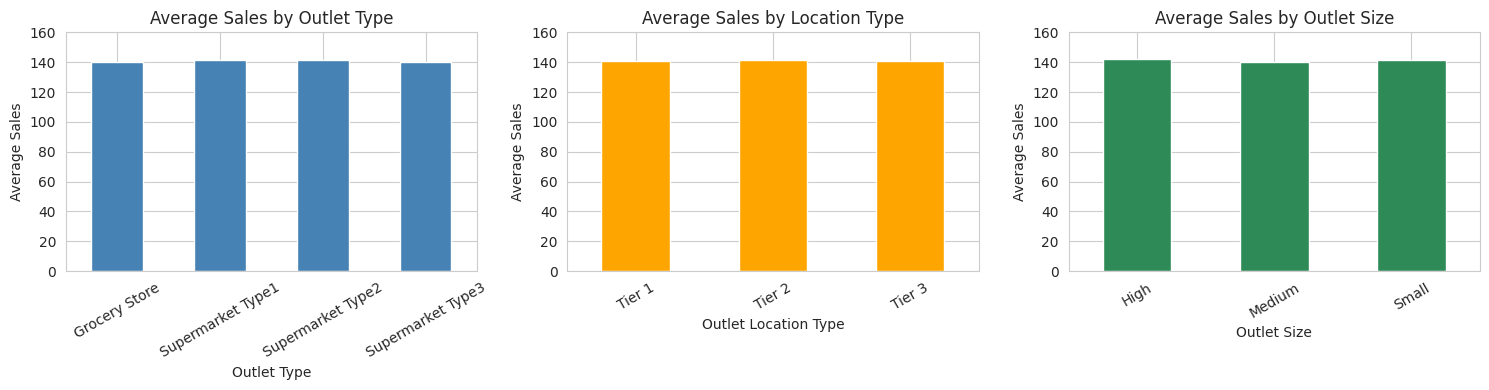

In [44]:
# Total sales is affected by the number of outlets and records, so let me also look at the average sales
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

type_sales['Average_Sales'].plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Average Sales by Outlet Type')

loc_sales['Average_Sales'].plot(kind='bar', ax=axes[1], color='orange')
axes[1].set_title('Average Sales by Location Type')

size_sales['Average_Sales'].plot(kind='bar', ax=axes[2], color='seagreen')
axes[2].set_title('Average Sales by Outlet Size')

for ax in axes:
    ax.set_ylabel('Average Sales')
    ax.set_ylim(0, 160)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

**Observation:**
- **Supermarket Type1** has the highest total sales (about 787,550, which is roughly 65% of all sales). But this is mainly because BlinkIT has **6 outlets** of this type. Supermarket Type2 and Type3 have only one outlet each and still earn about 131,000 each, which is very close to a single Type1 outlet.
- By location, **Tier 3** has the highest total sales (about 472,133) and Tier 1 the lowest (about 336,398), again partly because Tier 3 has 4 outlets and the others have 3.
- Looking at **average sales per record**, all outlet types, location tiers and sizes are almost the same (about 140 to 142). So no outlet type is clearly better at selling each product; the difference in total sales comes from how many products each outlet sells.
- The two **Grocery Stores (OUT010 and OUT019)** are the weakest outlets in total sales (about 78,000 and 74,000). The other 8 outlets earn about 129,000 to 133,000 each. Grocery stores have lower sales because they sell far fewer products (about 550 records vs about 930).

## Task 3.3: Are visibility, weight, ratings and outlet characteristics connected with sales?

In [45]:
# correlation of the numeric columns with sales
corr_cols = ['Item Visibility', 'Item Weight', 'Rating', 'Outlet Establishment Year', 'Sales']
corr = df[corr_cols].corr().round(3)
corr

,Item Visibility,Item Weight,Rating,Outlet Establishment Year,Sales
Item Visibility,1.000,-0.021,-0.004,-0.058,-0.006
Item Weight,-0.021,1.000,0.004,-0.002,0.026
Rating,-0.004,0.004,1.000,0.000,0.011
Outlet Establishment Year,-0.058,-0.002,0.000,1.000,-0.001
Sales,-0.006,0.026,0.011,-0.001,1.000


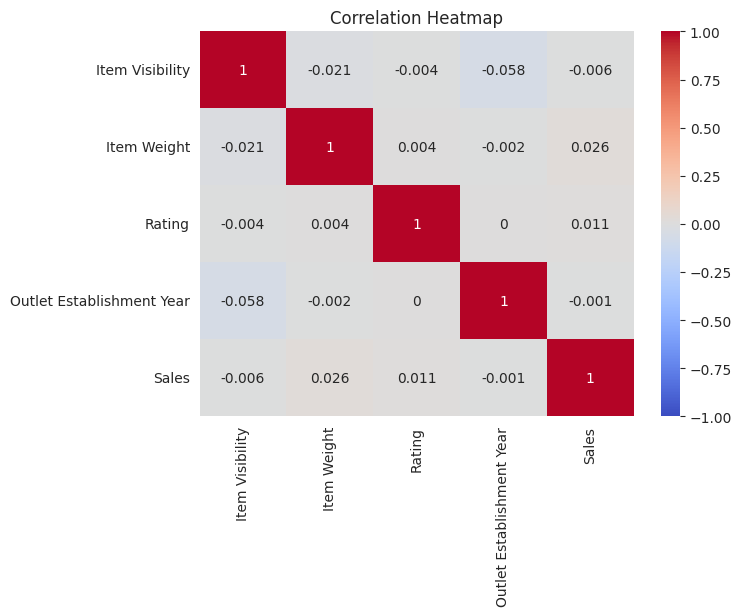

In [46]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

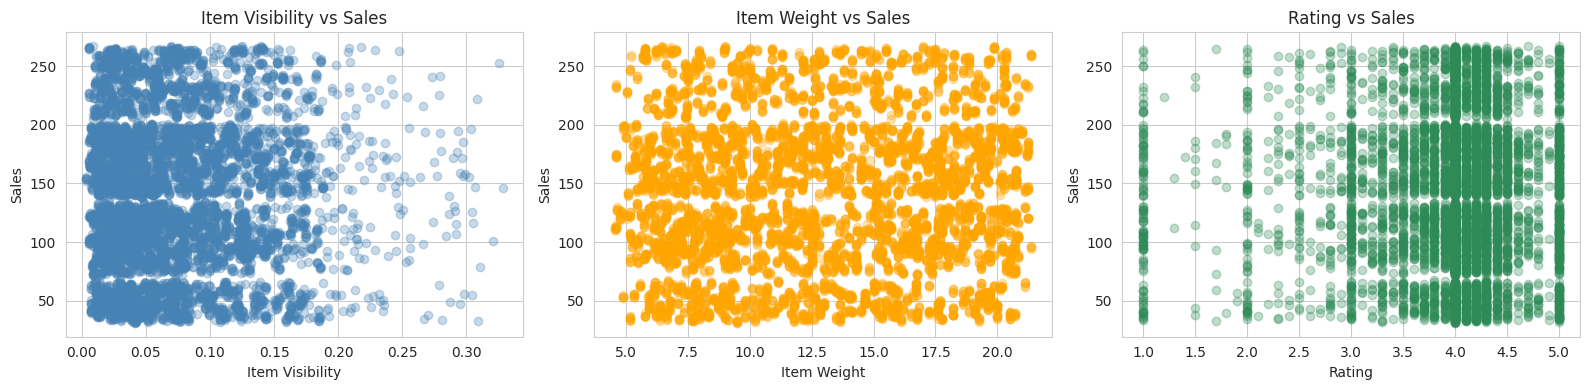

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(df['Item Visibility'], df['Sales'], alpha=0.3, color='steelblue')
axes[0].set_title('Item Visibility vs Sales')
axes[0].set_xlabel('Item Visibility')

axes[1].scatter(df['Item Weight'], df['Sales'], alpha=0.3, color='orange')
axes[1].set_title('Item Weight vs Sales')
axes[1].set_xlabel('Item Weight')

axes[2].scatter(df['Rating'], df['Sales'], alpha=0.3, color='seagreen')
axes[2].set_title('Rating vs Sales')
axes[2].set_xlabel('Rating')

for ax in axes:
    ax.set_ylabel('Sales')

plt.tight_layout()
plt.show()

In [48]:
# grouping visibility, weight and rating into bands and checking the average sales in each band
df['Visibility Group'] = pd.cut(df['Item Visibility'], bins=4, labels=['Very Low', 'Low', 'High', 'Very High'])
df['Weight Group'] = pd.cut(df['Item Weight'], bins=4, labels=['Very Light', 'Light', 'Heavy', 'Very Heavy'])
df['Rating Group'] = pd.cut(df['Rating'], bins=[0, 3, 3.5, 4, 5], labels=['Below 3', '3 to 3.5', '3.5 to 4', 'Above 4'])

print('Average Sales by Visibility Group')
print(df.groupby('Visibility Group', observed=False)['Sales'].mean().round(2))
print()
print('Average Sales by Weight Group')
print(df.groupby('Weight Group', observed=False)['Sales'].mean().round(2))
print()
print('Average Sales by Rating Group')
print(df.groupby('Rating Group', observed=False)['Sales'].mean().round(2))

Average Sales by Visibility Group
Visibility Group
Very Low     141.05
Low          141.41
High         137.81
Very High    140.00
Name: Sales, dtype: float64

Average Sales by Weight Group
Weight Group
Very Light    137.91
Light         141.89
Heavy         139.50
Very Heavy    144.71
Name: Sales, dtype: float64

Average Sales by Rating Group
Rating Group
Below 3     138.99
3 to 3.5    139.72
3.5 to 4    142.22
Above 4     139.92
Name: Sales, dtype: float64


In [49]:
# outlet establishment year vs sales
year_sales = df.groupby('Outlet Establishment Year')['Sales'].agg(['sum', 'mean', 'count']).round(2)
year_sales.columns = ['Total_Sales', 'Average_Sales', 'Number_of_Records']
year_sales

,Total_Sales,Average_Sales,Number_of_Records
Outlet Establishment Year,,,
2011,78131.57,140.78,555
2012,130476.86,140.30,930
2014,131809.02,141.43,932
2015,130942.78,140.95,929
2016,132113.37,142.06,930
2017,133103.91,143.12,930
2018,204522.26,139.80,1463
2020,129103.96,139.42,926
2022,131477.78,141.68,928


**Observation:**
- All correlations with Sales are **very close to 0** (visibility is about 0, weight is about 0.03, rating is about 0.01, establishment year is about 0). This means there is **no clear linear relationship** between sales and any of these factors.
- The scatter plots show a cloud of points with no pattern, which agrees with the correlation numbers.
- The average sales in every visibility, weight and rating group are close to each other (all between about 138 and 145) and do not go up or down in any steady way.
- So a higher rating, heavier product or more shelf space does **not** automatically give higher sales per record. Also, older outlets do not sell more per record than newer ones. (The year 2018 shows high total sales only because two outlets, OUT019 and OUT027, were both established that year.)

## Task 3.4: Compare better-performing and lower-performing products and outlets

In [50]:
# ---- Products: compare top 5 item types and bottom 5 item types (by total sales) ----
type_compare = df.groupby('Item Type').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Records=('Sales', 'count'),
    Unique_Products=('Item Identifier', 'nunique'),
    Avg_Rating=('Rating', 'mean'),
    Avg_Visibility=('Item Visibility', 'mean'),
    Avg_Weight=('Item Weight', 'mean')
).round(3).sort_values('Total_Sales', ascending=False)

print('TOP 5 item types')
display(type_compare.head(5))
print('BOTTOM 5 item types')
display(type_compare.tail(5))

TOP 5 item types


,Total_Sales,Average_Sales,Records,Unique_Products,Avg_Rating,Avg_Visibility,Avg_Weight
Item Type,,,,,,,
Fruits and Vegetables,178124.081,144.581,1232,220,3.956,0.074,13.237
Snack Foods,175433.922,146.195,1200,220,3.949,0.071,13.031
Household,135976.525,149.425,910,170,3.999,0.064,13.525
Frozen Foods,118558.881,138.503,856,155,3.971,0.070,12.782
Dairy,101276.462,148.499,682,125,3.966,0.077,13.380


BOTTOM 5 item types


,Total_Sales,Average_Sales,Records,Unique_Products,Avg_Rating,Avg_Visibility,Avg_Weight
Item Type,,,,,,,
Hard Drinks,29334.681,137.078,214,40,3.907,0.072,11.456
Others,22451.892,132.851,169,30,3.954,0.063,13.979
Starchy Foods,21880.027,147.838,148,30,3.920,0.074,13.841
Breakfast,15596.697,141.788,110,20,3.933,0.087,12.780
Seafood,9077.870,141.842,64,10,3.959,0.080,12.522


In [51]:
# ---- Individual products: top 10% vs bottom 10% by total sales ----
item_summary = df.groupby('Item Identifier').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Outlets_Selling=('Outlet Identifier', 'nunique'),
    Avg_Rating=('Rating', 'mean'),
    Avg_Visibility=('Item Visibility', 'mean'),
    Avg_Weight=('Item Weight', 'mean')
)

top_limit = item_summary['Total_Sales'].quantile(0.90)
low_limit = item_summary['Total_Sales'].quantile(0.10)

top_items = item_summary[item_summary['Total_Sales'] >= top_limit]
low_items = item_summary[item_summary['Total_Sales'] <= low_limit]

comparison = pd.DataFrame({
    'Top 10% Products': top_items.mean(),
    'Bottom 10% Products': low_items.mean()
}).round(3)

comparison

,Top 10% Products,Bottom 10% Products
Total_Sales,1595.401,204.236
Average_Sales,224.176,55.831
Outlets_Selling,7.186,4.250
Avg_Rating,3.965,3.985
Avg_Visibility,0.076,0.073
Avg_Weight,13.149,12.043


In [52]:
# ---- Outlets: best 3 vs weakest 3 outlets ----
outlet_compare = df.groupby('Outlet Identifier').agg(
    Total_Sales=('Sales', 'sum'),
    Average_Sales=('Sales', 'mean'),
    Records=('Sales', 'count'),
    Unique_Products=('Item Identifier', 'nunique'),
    Avg_Rating=('Rating', 'mean'),
    Avg_Visibility=('Item Visibility', 'mean')
).round(3).sort_values('Total_Sales', ascending=False)

outlet_compare['Outlet Type'] = outlet_info['Outlet Type']
outlet_compare['Location'] = outlet_info['Outlet Location Type']

print('BEST 3 outlets')
display(outlet_compare.head(3))
print('WEAKEST 3 outlets')
display(outlet_compare.tail(3))

BEST 3 outlets


,Total_Sales,Average_Sales,Records,Unique_Products,Avg_Rating,Avg_Visibility,Outlet Type,Location
Outlet Identifier,,,,,,,,
OUT035,133103.907,143.122,930,930,3.945,0.065,Supermarket Type1,Tier 2
OUT046,132113.370,142.057,930,930,3.958,0.066,Supermarket Type1,Tier 1
OUT013,131809.016,141.426,932,932,3.950,0.065,Supermarket Type1,Tier 3


WEAKEST 3 outlets


,Total_Sales,Average_Sales,Records,Unique_Products,Avg_Rating,Avg_Visibility,Outlet Type,Location
Outlet Identifier,,,,,,,,
OUT017,129103.960,139.421,926,926,3.982,0.066,Supermarket Type1,Tier 2
OUT010,78131.567,140.778,555,555,3.977,0.105,Grocery Store,Tier 3
OUT019,73807.582,139.787,528,528,3.995,0.112,Grocery Store,Tier 1


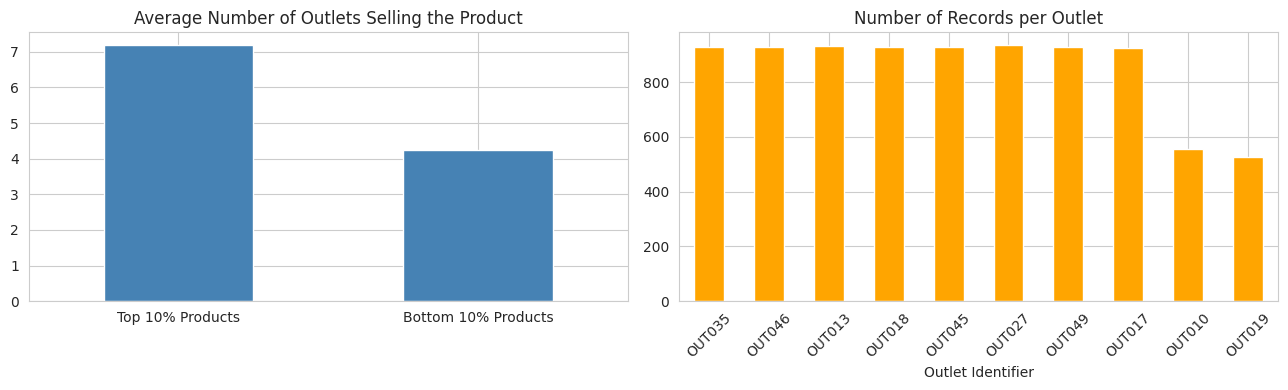

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

comparison.loc[['Outlets_Selling']].T.plot(kind='bar', ax=axes[0], color='steelblue', legend=False)
axes[0].set_title('Average Number of Outlets Selling the Product')
axes[0].tick_params(axis='x', rotation=0)

outlet_compare['Records'].plot(kind='bar', ax=axes[1], color='orange')
axes[1].set_title('Number of Records per Outlet')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Observation:**
- **Item types:** The top 5 item types have many more records and many more unique products than the bottom 5. Their average rating, visibility and weight are almost the same as the bottom 5. So the top types sell more mainly because **they have a wider range of products**, not because of better ratings or visibility.
- **Individual products:** The top 10% of products are sold in **more outlets** (about 7.2 on average) than the bottom 10% (about 4.3 on average), while their average rating (3.97 vs 3.99) and visibility (0.076 vs 0.073) are almost the same. So **availability across outlets** is the main difference between high and low selling products.
- **Outlets:** The two weakest outlets are the **Grocery Stores** (OUT010 and OUT019). They sell only 555 and 528 records vs about 930 for the others. Their average sale per record (about 140) and ratings (about 4.0) are as good as the best outlets. So the gap is the **smaller product range**, not poor quality or ratings.
- The Grocery Stores give each product a much bigger share of shelf space (average visibility about 0.11 vs about 0.065 in the other outlets), but this does not give them more sales per product. This is another sign that visibility does not drive sales.

---
# Objective 4: Help Management Make Better Business Decisions

## Task 4.1: Which products are contributing more to sales?

In [54]:
# share of each item type in total sales
type_share = df.groupby('Item Type')['Sales'].sum().sort_values(ascending=False)
type_share_percent = (type_share / type_share.sum() * 100).round(2)

top_types = pd.DataFrame({'Total_Sales': type_share.round(2), 'Share_%': type_share_percent})
top_types['Cumulative_Share_%'] = (type_share.cumsum() / type_share.sum() * 100).round(2)
top_types

,Total_Sales,Share_%,Cumulative_Share_%
Item Type,,,
Fruits and Vegetables,178124.08,14.82,14.82
Snack Foods,175433.92,14.60,29.42
Household,135976.53,11.32,40.74
Frozen Foods,118558.88,9.87,50.60
Dairy,101276.46,8.43,59.03
Canned,90706.73,7.55,66.58
Baking Goods,81894.74,6.82,73.39
Health and Hygiene,68025.84,5.66,79.06
Meat,59449.86,4.95,84.00


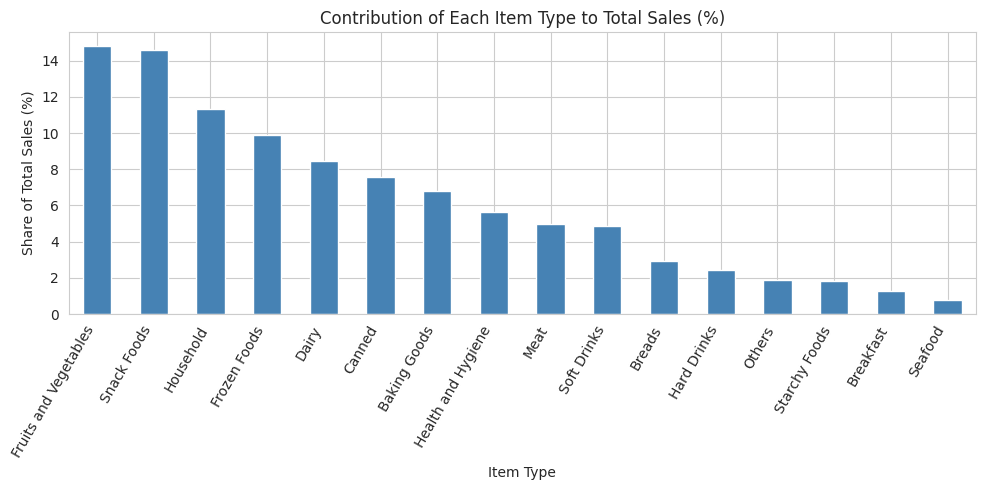

In [55]:
plt.figure(figsize=(10, 5))
top_types['Share_%'].plot(kind='bar', color='steelblue')
plt.title('Contribution of Each Item Type to Total Sales (%)')
plt.ylabel('Share of Total Sales (%)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [56]:
# top 10 individual products by total sales
top10_items = df.groupby(['Item Identifier', 'Item Type'])['Sales'].sum().sort_values(ascending=False).head(10).round(2)
top10_items

Item Identifier  Item Type            
FDU12            Baking Goods             2371.01
FDT07            Fruits and Vegetables    2306.90
NCQ06            Household                2294.71
FDL58            Snack Foods              2111.65
NCB31            Household                2104.73
FDX31            Fruits and Vegetables    2104.46
FDF05            Frozen Foods             2103.13
FDR59            Breads                   2096.58
FDP28            Frozen Foods             2087.85
FDA04            Frozen Foods             2072.07
Name: Sales, dtype: float64

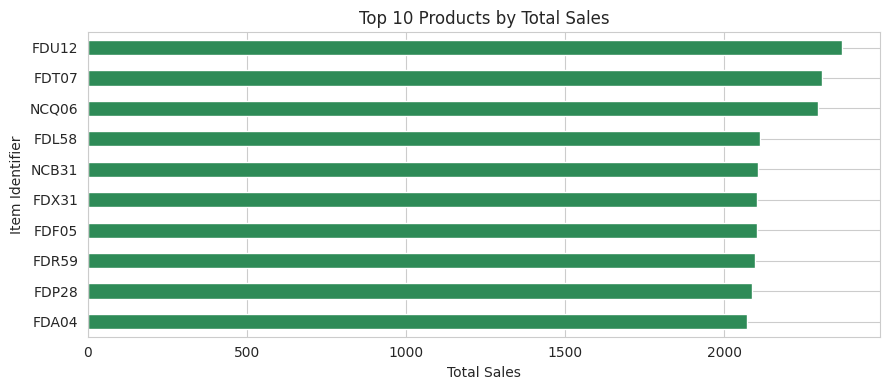

In [57]:
plt.figure(figsize=(9, 4))
df.groupby('Item Identifier')['Sales'].sum().sort_values(ascending=False).head(10).sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Products by Total Sales')
plt.xlabel('Total Sales')
plt.tight_layout()
plt.show()

**Observation:**
- **Fruits and Vegetables (about 14.8%), Snack Foods (about 14.6%) and Household (about 11.3%)** together make about 41% of total sales.
- The top 6 item types (adding Frozen Foods, Dairy and Canned) contribute about 67% of total sales, and the top 10 types about 89%.
- The best single products are **FDU12 (2,371), FDT07 (2,307) and NCQ06 (2,295)**. Each of them earns a little under 2,400 in total. Interestingly, FDU12 belongs to Baking Goods, the type with the lowest average sales, so even a weak category can have a star product.
- Sales are spread across many products and no single product dominates, so the business does not depend on any one item.

## Task 4.2: Which outlets and locations are performing better?

In [58]:
# outlet ranking with type and location
outlet_rank = outlet_compare[['Outlet Type', 'Location', 'Total_Sales', 'Average_Sales', 'Avg_Rating']].copy()
outlet_rank['Rank'] = range(1, len(outlet_rank) + 1)
outlet_rank

,Outlet Type,Location,Total_Sales,Average_Sales,Avg_Rating,Rank
Outlet Identifier,,,,,,
OUT035,Supermarket Type1,Tier 2,133103.907,143.122,3.945,1
OUT046,Supermarket Type1,Tier 1,132113.370,142.057,3.958,2
OUT013,Supermarket Type1,Tier 3,131809.016,141.426,3.950,3
OUT018,Supermarket Type2,Tier 3,131477.776,141.679,3.971,4
OUT045,Supermarket Type1,Tier 2,130942.780,140.950,3.960,5
OUT027,Supermarket Type3,Tier 3,130714.675,139.802,3.953,6
OUT049,Supermarket Type1,Tier 1,130476.860,140.298,3.985,7
OUT017,Supermarket Type1,Tier 2,129103.960,139.421,3.982,8
OUT010,Grocery Store,Tier 3,78131.567,140.778,3.977,9


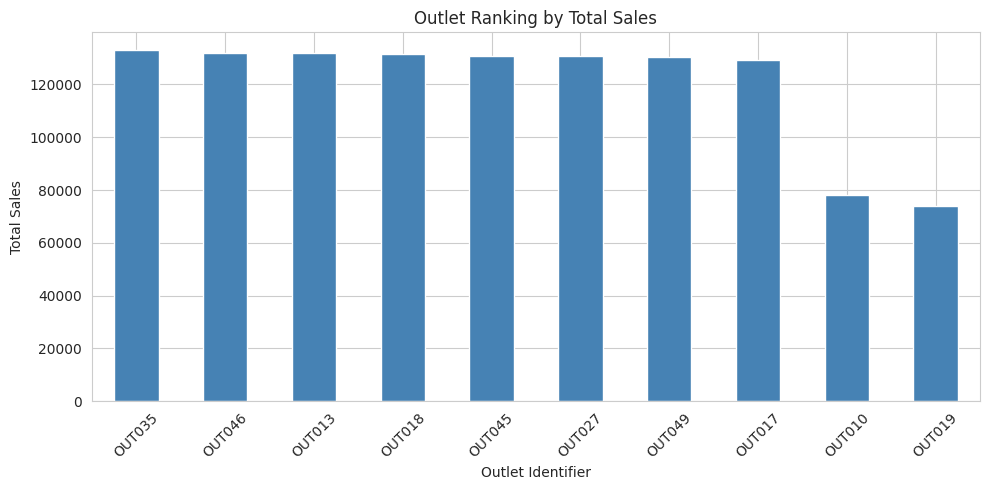

In [59]:
plt.figure(figsize=(10, 5))
outlet_rank['Total_Sales'].plot(kind='bar', color='steelblue')
plt.title('Outlet Ranking by Total Sales')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [60]:
# sales by outlet type and location together
pd.pivot_table(df, values='Sales', index='Outlet Type', columns='Outlet Location Type', aggfunc='sum').fillna(0).round(0)

Outlet Location Type,Tier 1,Tier 2,Tier 3
Outlet Type,,,
Grocery Store,73808.0,0.0,78132.0
Supermarket Type1,262590.0,393151.0,131809.0
Supermarket Type2,0.0,0.0,131478.0
Supermarket Type3,0.0,0.0,130715.0


In [61]:
# average total sales PER OUTLET in each location tier (fair comparison, because tiers have different number of outlets)
tier = df.groupby('Outlet Location Type').agg(
    Total_Sales=('Sales', 'sum'),
    Number_of_Outlets=('Outlet Identifier', 'nunique')
)
tier['Sales_per_Outlet'] = (tier['Total_Sales'] / tier['Number_of_Outlets']).round(0)
tier

,Total_Sales,Number_of_Outlets,Sales_per_Outlet
Outlet Location Type,,,
Tier 1,336397.8120,3,112133.0
Tier 2,393150.6476,3,131050.0
Tier 3,472133.0332,4,118033.0


**Observation:**
- The best outlets by total sales are **OUT035 (about 133,104), OUT046 (about 132,113), OUT013 (about 131,809) and OUT018 (about 131,478)**. The 8 full-range outlets are all very close (about 129,000 to 133,000), so there is no big gap between them.
- **OUT010 and OUT019 (Grocery Stores)** are clearly the lowest performers.
- By location tier, **Tier 3** has the highest total sales, but when we divide by the number of outlets, **Tier 2 has the highest sales per outlet (about 131,050)**, followed by Tier 3 (about 118,033) and Tier 1 (about 112,133). Tier 1 and Tier 3 are pulled down by their Grocery Stores.

## Task 4.3: Where can performance be improved?

In [62]:
# 1. item types with the lowest average sales per record
print('Lowest 5 item types by average sales:')
print(item_sales['Average_Sales'].sort_values().head(5))
print()

# 2. item types with the lowest total sales
print('Lowest 5 item types by total sales:')
print(item_sales['Total_Sales'].sort_values().head(5))

Lowest 5 item types by average sales:
Item Type
Baking Goods          126.38
Health and Hygiene    130.82
Soft Drinks           131.49
Others                132.85
Hard Drinks           137.08
Name: Average_Sales, dtype: float64

Lowest 5 item types by total sales:
Item Type
Seafood           9077.87
Breakfast        15596.70
Starchy Foods    21880.03
Others           22451.89
Hard Drinks      29334.68
Name: Total_Sales, dtype: float64


In [63]:
# 3. low rated records (rating below 3)
low_rating = df[df['Rating'] < 3]
print('Records with rating below 3:', len(low_rating))
print('Percentage of all records  :', round(len(low_rating) / len(df) * 100, 2), '%')
print()
print('Item types with most low ratings:')
print(low_rating['Item Type'].value_counts().head(5))

Records with rating below 3: 424
Percentage of all records  : 4.97 %

Item types with most low ratings:
Item Type
Fruits and Vegetables    63
Snack Foods              62
Frozen Foods             44
Household                36
Soft Drinks              34
Name: count, dtype: int64


In [64]:
# 4. share of low ratings in each item type (a fair comparison)
low_rating_share = (df.assign(Low=df['Rating'] < 3).groupby('Item Type')['Low'].mean() * 100).round(2)
low_rating_share.sort_values(ascending=False).head(5)

Item Type
Soft Drinks    7.64
Breads         7.57
Hard Drinks    7.48
Breakfast      6.36
Snack Foods    5.17
Name: Low, dtype: float64

In [65]:
# 5. data quality problems found earlier (original data)
print('Missing weights in raw data     :', df_raw['Item Weight'].isnull().sum())
print('Zero visibility in raw data     :', (df_raw['Item Visibility'] == 0).sum())
print('Messy fat content labels in raw :', df_raw['Item Fat Content'].nunique(), '(should be 2)')

Missing weights in raw data     : 1463
Zero visibility in raw data     : 526
Messy fat content labels in raw : 5 (should be 2)


**Observation: areas where performance can be improved**

*Products*
- **Baking Goods** (avg 126.4), **Health and Hygiene** (130.8) and **Soft Drinks** (131.5) have the lowest average sales per record. **Seafood, Breakfast and Starchy Foods** have the lowest total sales because very few products are sold in them.

*Outlets*
- The two **Grocery Stores (OUT010 and OUT019)** and the **Tier 1 / Tier 3** locations that contain them have the most room to grow, as they sell far fewer products than the other outlets.

*Customer ratings*
- About **5% of records (424)** have a rating below 3. Ratings do not change sales much, but low ratings still show unhappy customers.
- The item types with the highest share of low ratings are **Soft Drinks (7.6%), Breads (7.6%) and Hard Drinks (7.5%)**. Soft Drinks is also one of the lowest in average sales, so the whole **Drinks** group needs attention.

*Data quality*
- Weight is not recorded at OUT019 and OUT027, visibility is 0 in 526 records, fat content labels were inconsistent, and Outlet Size is unreliable for 3 outlets. These should be fixed at the source.

## Task 4.4: Practical suggestions to improve sales and business performance

Based on the analysis, my suggestions to management are:

**1. Increase the product range in the Grocery Stores (OUT010, OUT019)**
These two outlets sell about 40% fewer records than the others, but their average sale per record and customer ratings are as good as the best outlets. Adding more products here is the easiest way to grow their sales.

**2. Make successful products available in more outlets**
Top-selling products are sold in about 7 outlets on average, compared with about 4 for the lowest-selling products, with similar ratings and visibility. Rolling out good products to more outlets should increase total sales.

**3. Keep strong focus on the top categories, and grow the high-average categories**
Fruits and Vegetables, Snack Foods, Household, Frozen Foods, Dairy and Canned give about 67% of sales, so they should always be in stock. Household and Dairy also have the best average sales per record, so they are good categories to expand.

**4. Review the weak categories**
Baking Goods, Health and Hygiene and Soft Drinks have the lowest average sales per record, and the Drinks group (Soft Drinks and Hard Drinks) also has the highest share of low ratings. Management should review pricing, offers, quality and stock for these. Seafood, Breakfast and Starchy Foods sell little because they have few products, so a wider range could be tested.

**5. Do not depend only on shelf visibility, weight or rating to increase sales**
These factors showed almost no relationship with sales, so spending extra effort on shelf space alone is unlikely to boost sales. Offers, pricing and range are better areas to focus on.

**6. Use Tier 2 as a model and review Tier 1 and Tier 3**
Tier 2 outlets have the highest sales per outlet. Tier 1 and Tier 3 should look at why their Grocery Stores sell less, and whether upgrading them to supermarkets would help.

**7. Handle low-rated products**
About 5% of records have a rating below 3, and it is highest in Soft Drinks, Breads and Hard Drinks (about 7.5% each). These products should be checked for quality or delivery problems to improve customer satisfaction.

**8. Improve data collection**
Record weight at all outlets, avoid 0 visibility values, use fixed labels for fat content, and keep one Outlet Size per outlet. This will make future analysis more reliable.

---
# Final Summary

| Area | Key Finding |
|---|---|
| **Business size** | 8,523 records, 1,559 products, 16 item types, 10 outlets, total sales of about 1.20 million |
| **Data quality** | Missing weights (17%), 526 zero visibility values, messy fat content labels, unreliable outlet size for 3 outlets were found and handled. No duplicates |
| **Top products** | Fruits and Vegetables, Snack Foods and Household give about 41% of total sales. The top 6 types give about 67% |
| **Top outlets** | OUT035, OUT046, OUT013 and OUT018. The 8 full-range outlets are all about equal |
| **Weak outlets** | The two Grocery Stores (OUT010, OUT019) sell far fewer products |
| **Sales drivers** | Visibility, weight, rating and outlet age have almost no relation with sales. Product range and number of outlets selling the product matter more |
| **Customer rating** | Average rating is about 3.97 out of 5, and only about 5% of records are below 3 |

**Conclusion:** BlinkIT is performing evenly and well in most outlets. The biggest chances to grow are to widen the product range (especially in Grocery Stores), launch good products in more outlets, and review the weaker categories.